## Dependencies

This notebook requires `numpy`, `pandas`, and `matplotlib`.

# Replay protection experiment analysis

This notebook reads the runner's raw observations and recomputes metrics rather than using fabricated sample results. Choose an experiment directory generated by `run-local-demo-2.js` in the first code cell. Latencies are runner-observed end-to-end HTTP timings; store latency is reported separately.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

experiment_dir = Path('../results/replay-2026-11-11T07-38-20-847Z-cdda86af').resolve()  # Set this to a generated run directory.
metadata = json.loads((experiment_dir / 'metadata.json').read_text())
requests = pd.read_csv(experiment_dir / 'requests.csv')
scenarios = pd.read_csv(experiment_dir / 'scenarios.csv')
summary = pd.read_csv(experiment_dir / 'summary.csv')

required_request_columns = {
    'experiment_id', 'scenario_id', 'method', 'replica_count', 'repetition',
    'phase', 'jti_hash', 'replica_id', 'latency_ms', 'actual_outcome',
    'replay_detected', 'legitimate_request', 'request_start_timestamp',
    'request_end_timestamp', 'store_latency_ms'
}
assert required_request_columns <= set(requests.columns)
assert {'scenario_id', 'status', 'completed_requests'} <= set(scenarios.columns)
assert {'scenario_id', 'latency_mean_ms', 'replay_detection_rate'} <= set(summary.columns)
metadata['experiment_id']

'replay-2026-11-11T07-38-20-847Z-cdda86af'

In [2]:
print('requests:', requests.shape, 'scenarios:', scenarios.shape, 'summary:', summary.shape)
display(pd.DataFrame({
    'requests': requests.isna().sum(),
    'scenarios': scenarios.isna().sum(),
    'summary': summary.isna().sum(),
}).fillna(0).astype(int))
display(scenarios)

requests: (10170, 26) scenarios: (18, 18) summary: (18, 25)


,requests,scenarios,summary
accepted_requests,0,0,0
actual_outcome,0,0,0
completed_requests,0,0,0
concurrency_level,0,0,0
cpu_usage,0,0,18
cross_replica_replay_detection_rate,0,0,9
end_time,0,0,0
error_category,10170,0,0
error_count,0,0,0
error_message,10170,0,0


,experiment_id,scenario_id,method,replica_count,repetition,planned_requests,completed_requests,accepted_requests,rejected_requests,replay_attempts,replay_blocked,legitimate_requests,legitimate_accepted,error_count,status,reason,start_time,end_time
0,replay-2026-11-11T07-38-20-847Z-cdda86af,S1,in-memory,1,1,564,564,405,159,160,159,404,404,0,completed,NaN,2026-11-11T07:38:21.193090221Z,2026-11-11T07:38:23.937667662Z
1,replay-2026-11-11T07-38-20-847Z-cdda86af,S1,in-memory,1,2,564,564,405,159,160,159,404,404,0,completed,NaN,2026-11-11T07:38:23.954353349Z,2026-11-11T07:38:26.609521712Z
2,replay-2026-11-11T07-38-20-847Z-cdda86af,S1,in-memory,1,3,564,564,405,159,160,159,404,404,0,completed,NaN,2026-11-11T07:38:26.624261386Z,2026-11-11T07:38:29.420214487Z
3,replay-2026-11-11T07-38-20-847Z-cdda86af,S2,redis,1,1,564,564,404,160,160,160,404,404,0,completed,NaN,2026-11-11T07:38:29.435937424Z,2026-11-11T07:38:32.344259538Z
4,replay-2026-11-11T07-38-20-847Z-cdda86af,S2,redis,1,2,564,564,404,160,160,160,404,404,0,completed,NaN,2026-11-11T07:38:32.360661938Z,2026-11-11T07:38:35.052281173Z
5,replay-2026-11-11T07-38-20-847Z-cdda86af,S2,redis,1,3,564,564,404,160,160,160,404,404,0,completed,NaN,2026-11-11T07:38:35.067629981Z,2026-11-11T07:38:37.762720600Z
6,replay-2026-11-11T07-38-20-847Z-cdda86af,S3,redis-ttl,1,1,564,564,404,160,160,160,404,404,0,completed,NaN,2026-11-11T07:38:37.785950583Z,2026-11-11T07:38:40.608004919Z
7,replay-2026-11-11T07-38-20-847Z-cdda86af,S3,redis-ttl,1,2,564,564,404,160,160,160,404,404,0,completed,NaN,2026-11-11T07:38:40.625140775Z,2026-11-11T07:38:43.412891077Z
8,replay-2026-11-11T07-38-20-847Z-cdda86af,S3,redis-ttl,1,3,564,564,404,160,160,160,404,404,0,completed,NaN,2026-11-11T07:38:43.434916377Z,2026-11-11T07:38:46.240143816Z
9,replay-2026-11-11T07-38-20-847Z-cdda86af,S4,in-memory,2,1,566,566,409,157,161,157,405,405,0,completed,NaN,2026-11-11T07:38:46.257753932Z,2026-11-11T07:38:49.548763803Z


## Security rates

Replay detection rate is replay rejections divided by replay attempts. In a concurrent batch, `n - 1` requests are replay attempts because one request is the expected first use. Legitimate acceptance rate is accepted legitimate requests divided by legitimate requests.

In [3]:
requests['replay_detected'] = requests['replay_detected'].astype(str).str.lower().eq('true')
requests['legitimate_request'] = requests['legitimate_request'].astype(str).str.lower().eq('true')
security_rows = []
keys = ['scenario_id', 'method', 'replica_count', 'repetition']
for key, group in requests.groupby(keys, dropna=False):
    replay = group[group.phase == 'replay']
    concurrent = group[group.phase == 'concurrent_replay']
    # Exclude one expected first-use request per concurrent jti from the replay denominator.
    concurrent_replays = int(concurrent.groupby('jti_hash').size().sub(1).clip(lower=0).sum())
    replay_attempts = len(replay) + concurrent_replays
    concurrent_replay_rows = concurrent[~concurrent.legitimate_request]
    replay_blocked = int(replay.replay_detected.sum() + concurrent_replay_rows.replay_detected.sum())
    legitimate = group[group.legitimate_request]
    legitimate_accepted = int((legitimate.actual_outcome == 'accepted').sum())
    security_rows.append({
        **dict(zip(keys, key)),
        'replay_detection_rate': replay_blocked / replay_attempts if replay_attempts else np.nan,
        'legitimate_request_acceptance_rate': legitimate_accepted / len(legitimate) if len(legitimate) else np.nan,
        'false_acceptance_count': int((replay.actual_outcome == 'accepted').sum()) + max(0, int((concurrent.actual_outcome == 'accepted').sum()) - concurrent.jti_hash.nunique()),
        'cross_replica_replay_detection_rate': replay.loc[replay.replay_context == 'cross_replica', 'replay_detected'].mean(),
    })
security = pd.DataFrame(security_rows)
display(security)

,scenario_id,method,replica_count,repetition,replay_detection_rate,legitimate_request_acceptance_rate,false_acceptance_count,cross_replica_replay_detection_rate
0,S1,in-memory,1,1,0.993750,1.0,1,NaN
1,S1,in-memory,1,2,0.993750,1.0,1,NaN
2,S1,in-memory,1,3,0.993750,1.0,1,NaN
3,S2,redis,1,1,1.000000,1.0,0,NaN
4,S2,redis,1,2,1.000000,1.0,0,NaN
5,S2,redis,1,3,1.000000,1.0,0,NaN
6,S3,redis-ttl,1,1,1.000000,1.0,0,NaN
7,S3,redis-ttl,1,2,1.000000,1.0,0,NaN
8,S3,redis-ttl,1,3,1.000000,1.0,0,NaN
9,S4,in-memory,2,1,0.975155,1.0,4,0.0


## Latency and throughput

The latency distribution uses only raw `performance` requests. Mean, median, sample standard deviation (`ddof=1`), p95, and p99 use the request observations directly. Throughput is completed performance requests divided by the span between the earliest request start and latest request end within each concurrency window.

In [4]:
requests['latency_ms'] = pd.to_numeric(requests['latency_ms'], errors='coerce')
requests['store_latency_ms'] = pd.to_numeric(requests['store_latency_ms'], errors='coerce')
requests['request_start_timestamp'] = pd.to_datetime(requests.request_start_timestamp, utc=True, errors='coerce')
requests['request_end_timestamp'] = pd.to_datetime(requests.request_end_timestamp, utc=True, errors='coerce')
performance = requests[requests.phase == 'performance'].copy()
latency_metrics = performance.groupby(keys, dropna=False).latency_ms.agg(
    latency_mean_ms='mean', latency_median_ms='median', latency_std_ms='std'
).reset_index()
percentiles = performance.groupby(keys, dropna=False).latency_ms.agg(
    latency_p95_ms=lambda values: values.quantile(.95, interpolation='linear'),
    latency_p99_ms=lambda values: values.quantile(.99, interpolation='linear'),
).reset_index()
latency_metrics = latency_metrics.merge(percentiles, on=keys, how='left')
display(latency_metrics)

throughput_rows = []
for group_key, group in performance.groupby(keys + ['concurrency_level'], dropna=False):
    group = group.dropna(subset=['request_start_timestamp', 'request_end_timestamp'])
    duration = (group.request_end_timestamp.max() - group.request_start_timestamp.min()).total_seconds() if len(group) else np.nan
    throughput_rows.append({
        **dict(zip(keys + ['concurrency_level'], group_key)),
        'completed_requests': len(group),
        'measurement_duration_seconds': duration,
        'throughput_rps': len(group) / duration if duration and duration > 0 else np.nan,
    })
throughput = pd.DataFrame(throughput_rows)
display(throughput)

,scenario_id,method,replica_count,repetition,latency_mean_ms,latency_median_ms,latency_std_ms,latency_p95_ms,latency_p99_ms
0,S1,in-memory,1,1,33.875476,16.788061,34.404723,89.916068,97.062989
1,S1,in-memory,1,2,33.373050,17.487439,33.561290,86.093079,89.449822
2,S1,in-memory,1,3,37.201942,17.328336,38.535488,97.929826,102.178931
3,S2,redis,1,1,48.557715,19.971024,53.934281,140.851173,142.459406
4,S2,redis,1,2,34.685243,17.303378,35.353393,92.769201,95.548321
5,S2,redis,1,3,36.945177,18.082017,38.496320,104.722432,107.847178
6,S3,redis-ttl,1,1,37.828379,19.351378,38.509616,101.238071,102.972991
7,S3,redis-ttl,1,2,38.154497,19.191128,38.842028,100.008217,105.266886
8,S3,redis-ttl,1,3,45.735715,18.448088,49.721077,124.164125,127.190912
9,S4,in-memory,2,1,39.098040,18.548364,40.190991,106.341733,108.717026


,scenario_id,method,replica_count,repetition,concurrency_level,completed_requests,measurement_duration_seconds,throughput_rps
0,S1,in-memory,1,1,1,100,0.401058,249.340713
1,S1,in-memory,1,1,10,100,0.218646,457.360778
2,S1,in-memory,1,1,50,100,0.198491,503.800175
3,S1,in-memory,1,2,1,100,0.377699,264.761374
4,S1,in-memory,1,2,10,100,0.222123,450.200526
5,S1,in-memory,1,2,50,100,0.189218,528.490103
6,S1,in-memory,1,3,1,100,0.426701,234.356088
7,S1,in-memory,1,3,10,100,0.218060,458.589205
8,S1,in-memory,1,3,50,100,0.212199,471.255358
9,S2,redis,1,1,1,100,0.386879,258.478997


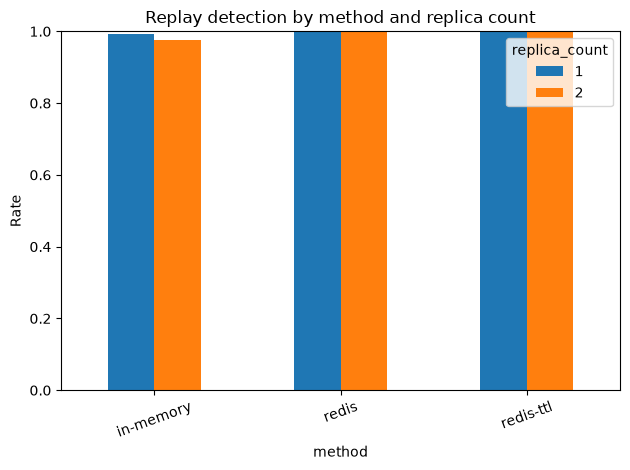

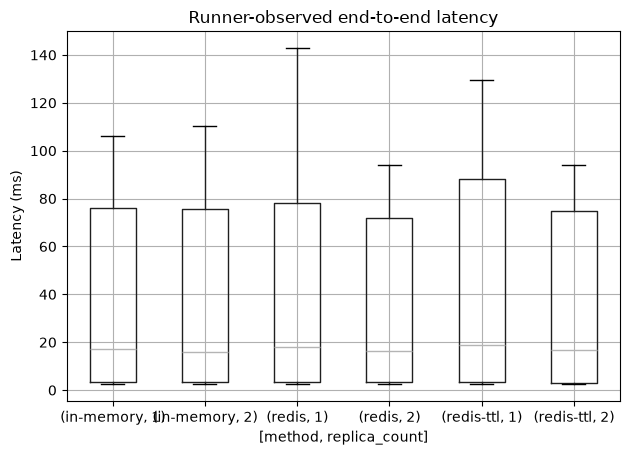

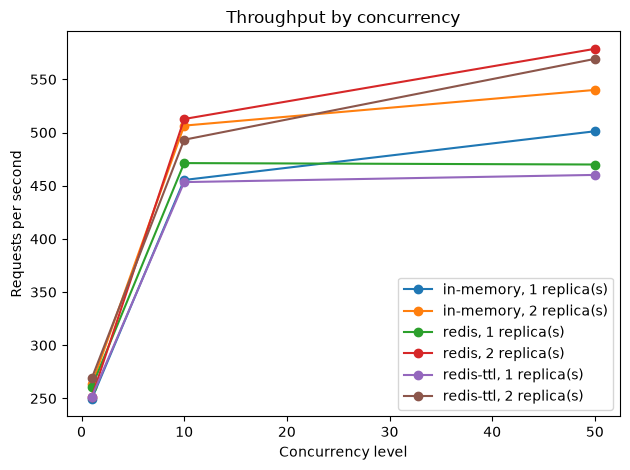

,method,replica_count,replay_detection_rate,legitimate_request_acceptance_rate
0,in-memory,1,0.993750,1.0
1,in-memory,2,0.975155,1.0
2,redis,1,1.000000,1.0
3,redis,2,1.000000,1.0
4,redis-ttl,1,1.000000,1.0
5,redis-ttl,2,1.000000,1.0


In [5]:
analysis_dir = experiment_dir / 'analysis'
analysis_dir.mkdir(exist_ok=True)
security.to_csv(analysis_dir / 'notebook_security_metrics.csv', index=False)
latency_metrics.to_csv(analysis_dir / 'notebook_latency_metrics.csv', index=False)
throughput.to_csv(analysis_dir / 'notebook_throughput.csv', index=False)

comparison = (security.groupby(['method', 'replica_count'], as_index=False).agg(
    replay_detection_rate=('replay_detection_rate', 'mean'),
    legitimate_request_acceptance_rate=('legitimate_request_acceptance_rate', 'mean'),
) if not security.empty else pd.DataFrame())
if not comparison.empty:
    comparison.pivot(index='method', columns='replica_count', values='replay_detection_rate').plot(
        kind='bar', ylim=(0, 1), rot=20, title='Replay detection by method and replica count'
    )
    plt.ylabel('Rate')
    plt.tight_layout()
    plt.savefig(analysis_dir / 'notebook_security_rates.png', dpi=150)
    plt.show()

if not performance.empty:
    performance.boxplot(column='latency_ms', by=['method', 'replica_count'])
    plt.suptitle('')
    plt.title('Runner-observed end-to-end latency')
    plt.ylabel('Latency (ms)')
    plt.tight_layout()
    plt.savefig(analysis_dir / 'notebook_latency.png', dpi=150)
    plt.show()

if not throughput.empty:
    for (method, replica_count), group in throughput.groupby(['method', 'replica_count']):
        group.groupby('concurrency_level').throughput_rps.mean().sort_index().plot(
            marker='o', label=f'{method}, {replica_count} replica(s)'
        )
    plt.title('Throughput by concurrency')
    plt.xlabel('Concurrency level')
    plt.ylabel('Requests per second')
    plt.legend()
    plt.tight_layout()
    plt.savefig(analysis_dir / 'notebook_throughput.png', dpi=150)
    plt.show()
display(comparison)

## Independent validation and audit

Bagian ini menambahkan pemeriksaan independen atas integritas raw data, rekalkulasi metrik keamanan, perilaku concurrent/cross-replica/restart, serta konsistensi metadata dengan source code.

Jalankan seluruh notebook dari atas ke bawah. Pemeriksaan ini **tidak mengubah raw data maupun implementasi eksperimen**. Hasil `PASS` berarti pemeriksaan yang didefinisikan di sini terpenuhi; hasil `REVIEW` menandai temuan yang perlu dijelaskan dalam laporan, bukan otomatis membatalkan eksperimen.

In [6]:
# 1. Raw-data integrity checks
from pathlib import Path
import json
import pandas as pd
import numpy as np

validation_checks = []

def add_check(name, passed, detail):
    validation_checks.append({
        "check": name,
        "status": "PASS" if bool(passed) else "REVIEW",
        "detail": str(detail)
    })

required_files = ["metadata.json", "requests.csv", "scenarios.csv", "summary.csv", "events.jsonl"]
missing_files = [name for name in required_files if not (experiment_dir / name).exists()]
add_check("Required experiment files", not missing_files,
          "All required files exist" if not missing_files else f"Missing: {missing_files}")

add_check("Request count matches metadata",
          len(requests) == metadata.get("request_counts", {}).get("completed_measured_requests"),
          f"requests.csv={len(requests)}; metadata={metadata.get('request_counts', {}).get('completed_measured_requests')}")

add_check("Scenario count",
          len(scenarios) == 18 and scenarios["scenario_id"].nunique() == 6,
          f"{len(scenarios)} scenario-repetition rows; {scenarios['scenario_id'].nunique()} unique scenarios")

add_check("No duplicate request IDs",
          requests["request_id"].notna().all() and not requests["request_id"].duplicated().any(),
          f"duplicate IDs={int(requests['request_id'].duplicated().sum())}")

critical_request_cols = [
    "experiment_id", "scenario_id", "method", "replica_count", "repetition",
    "phase", "request_id", "jti_hash", "actual_outcome",
    "request_start_timestamp", "request_end_timestamp"
]
missing_critical = requests[critical_request_cols].isna().sum()
add_check("Critical request fields populated",
          int(missing_critical.sum()) == 0,
          f"missing values={int(missing_critical.sum())}")

add_check("All scenario repetitions completed",
          scenarios["status"].eq("completed").all() and
          (pd.to_numeric(scenarios["planned_requests"], errors="coerce") ==
           pd.to_numeric(scenarios["completed_requests"], errors="coerce")).all(),
          f"statuses={scenarios['status'].value_counts(dropna=False).to_dict()}")

add_check("No store/service errors",
          int(scenarios["error_count"].fillna(0).sum()) == 0,
          f"scenario error_count total={int(scenarios['error_count'].fillna(0).sum())}")

integrity_report = pd.DataFrame(validation_checks)
display(integrity_report)

,check,status,detail
0,Required experiment files,PASS,All required files exist
1,Request count matches metadata,PASS,requests.csv=10170; metadata=10170
2,Scenario count,PASS,18 scenario-repetition rows; 6 unique scenarios
3,No duplicate request IDs,PASS,duplicate IDs=0
4,Critical request fields populated,PASS,missing values=0
5,All scenario repetitions completed,PASS,statuses={'completed': 18}
6,No store/service errors,PASS,scenario error_count total=0


### 2. Rekalkulasi metrik keamanan dari raw observations

Bagian ini menghitung ulang detection rate, legitimate acceptance, false rejection, dan false acceptance langsung dari `requests.csv`, lalu membandingkannya dengan `summary.csv`.

Untuk concurrent replay, denominator replay adalah jumlah request dalam setiap kelompok `jti` dikurangi satu penggunaan pertama yang diharapkan. Dengan demikian, concurrency 1 menghasilkan nol replay attempt; concurrency 10 menghasilkan 9; concurrency 50 menghasilkan 49.

In [7]:
# 2. Independent security-metric recalculation and comparison
raw = requests.copy()
for col in ["replay_detected", "legitimate_request"]:
    raw[col] = raw[col].astype(str).str.lower().eq("true")

audit_rows = []
for group_key, group in raw.groupby(keys, dropna=False):
    replay_rows = group[group["phase"] == "replay"]
    concurrent_rows = group[group["phase"] == "concurrent_replay"]

    concurrent_replay_denominator = int(
        concurrent_rows.groupby("jti_hash").size().sub(1).clip(lower=0).sum()
    )
    replay_denominator = len(replay_rows) + concurrent_replay_denominator

    concurrent_replay_rows = concurrent_rows[~concurrent_rows["legitimate_request"]]
    blocked = int(replay_rows["replay_detected"].sum() +
                  concurrent_replay_rows["replay_detected"].sum())

    legitimate_rows = group[group["legitimate_request"]]
    legitimate_accepted = int((legitimate_rows["actual_outcome"] == "accepted").sum())
    legitimate_rejected = len(legitimate_rows) - legitimate_accepted

    concurrent_over_acceptances = sum(
        max(0, int((batch["actual_outcome"] == "accepted").sum()) - 1)
        for _, batch in concurrent_rows.groupby("jti_hash")
    )
    concurrent_over_acceptances = max(0, concurrent_over_acceptances)

    replay_accepted = int((replay_rows["actual_outcome"] == "accepted").sum()) + concurrent_over_acceptances

    audit_rows.append({
        **dict(zip(keys, group_key)),
        "replay_attempts": replay_denominator,
        "replay_blocked": blocked,
        "replay_detection_rate_independent": blocked / replay_denominator if replay_denominator else np.nan,
        "legitimate_requests": len(legitimate_rows),
        "legitimate_accepted": legitimate_accepted,
        "legitimate_acceptance_rate_independent": legitimate_accepted / len(legitimate_rows) if len(legitimate_rows) else np.nan,
        "false_rejection_rate_independent": legitimate_rejected / len(legitimate_rows) if len(legitimate_rows) else np.nan,
        "false_acceptance_count_independent": replay_accepted,
        "false_acceptance_rate_independent": replay_accepted / replay_denominator if replay_denominator else np.nan,
    })

independent_security = pd.DataFrame(audit_rows)
summary_compare = summary.merge(independent_security, on=keys, how="outer", validate="one_to_one")

for metric in [
    "replay_detection_rate",
    "legitimate_request_acceptance_rate",
    "false_rejection_rate",
    "false_acceptance_rate",
]:
    independent_col = {
        "replay_detection_rate": "replay_detection_rate_independent",
        "legitimate_request_acceptance_rate": "legitimate_acceptance_rate_independent",
        "false_rejection_rate": "false_rejection_rate_independent",
        "false_acceptance_rate": "false_acceptance_rate_independent",
    }[metric]
    summary_compare[f"{metric}_abs_diff"] = (
        pd.to_numeric(summary_compare[metric], errors="coerce") -
        pd.to_numeric(summary_compare[independent_col], errors="coerce")
    ).abs()

rate_diff_cols = [f"{name}_abs_diff" for name in [
    "replay_detection_rate", "legitimate_request_acceptance_rate",
    "false_rejection_rate", "false_acceptance_rate"
]]
max_rate_difference = summary_compare[rate_diff_cols].max().max()
add_check("Security rates reproduce summary.csv",
          pd.notna(max_rate_difference) and max_rate_difference < 1e-9,
          f"maximum absolute difference={max_rate_difference:.3g}")

display(summary_compare[keys + [
    "replay_attempts", "replay_blocked",
    "replay_detection_rate", "replay_detection_rate_independent",
    "legitimate_request_acceptance_rate", "legitimate_acceptance_rate_independent",
    "false_acceptance_rate", "false_acceptance_rate_independent"
]])
display(pd.DataFrame([{
    "maximum_absolute_rate_difference": max_rate_difference,
    "interpretation": "Rates independently reproduce summary.csv within numerical precision."
}]))

,scenario_id,method,replica_count,repetition,replay_attempts,replay_blocked,replay_detection_rate,replay_detection_rate_independent,legitimate_request_acceptance_rate,legitimate_acceptance_rate_independent,false_acceptance_rate,false_acceptance_rate_independent
0,S1,in-memory,1,1,160,159,0.993750,0.993750,1,1.0,0.006250,0.006250
1,S1,in-memory,1,2,160,159,0.993750,0.993750,1,1.0,0.006250,0.006250
2,S1,in-memory,1,3,160,159,0.993750,0.993750,1,1.0,0.006250,0.006250
3,S2,redis,1,1,160,160,1.000000,1.000000,1,1.0,0.000000,0.000000
4,S2,redis,1,2,160,160,1.000000,1.000000,1,1.0,0.000000,0.000000
5,S2,redis,1,3,160,160,1.000000,1.000000,1,1.0,0.000000,0.000000
6,S3,redis-ttl,1,1,160,160,1.000000,1.000000,1,1.0,0.000000,0.000000
7,S3,redis-ttl,1,2,160,160,1.000000,1.000000,1,1.0,0.000000,0.000000
8,S3,redis-ttl,1,3,160,160,1.000000,1.000000,1,1.0,0.000000,0.000000
9,S4,in-memory,2,1,161,157,0.975155,0.975155,1,1.0,0.024845,0.024845


,maximum_absolute_rate_difference,interpretation
0,0.0,Rates independently reproduce summary.csv with...


### 3. Validasi concurrent replay, cross-replica, dan restart

`outcome_correct` pada baris concurrent bukan indikator bahwa setiap baris secara individual harus memiliki outcome yang sama. Runner menandai **seluruh batch** sebagai tidak valid jika invariant batch (tepat satu request diterima untuk satu `jti`) gagal. Karena itu, validasi yang tepat dilakukan pada tingkat kelompok `jti` dan concurrency level.

In [8]:
# 3A. Concurrent replay invariant: exactly one accepted request per jti batch
concurrent = raw[raw["phase"] == "concurrent_replay"].copy()
concurrent_batches = concurrent.groupby(
    ["scenario_id", "method", "replica_count", "repetition", "concurrency_level", "jti_hash"],
    dropna=False
).agg(
    requests=("request_id", "size"),
    accepted=("actual_outcome", lambda s: int((s == "accepted").sum())),
    replay_rejected=("actual_outcome", lambda s: int((s == "replay_detected").sum())),
    other_outcomes=("actual_outcome", lambda s: int((~s.isin(["accepted", "replay_detected"])).sum()))
).reset_index()

# Expected observed behavior for this experiment:
# - Shared Redis state: one accepted request per batch.
# - In-memory with one replica: one accepted request per batch.
# - In-memory with two replicas: one acceptance at C=1, two at C=10/50
#   because each process maintains independent state.
def expected_acceptance(row):
    if row["method"] in ["redis", "redis-ttl"]:
        return 1
    if int(row["replica_count"]) == 1:
        return 1
    return min(int(row["replica_count"]), int(row["concurrency_level"]))

concurrent_batches["expected_accepted_for_observed_topology"] = concurrent_batches.apply(expected_acceptance, axis=1)
concurrent_batches["matches_observed_topology"] = (
    (concurrent_batches["accepted"] == concurrent_batches["expected_accepted_for_observed_topology"]) &
    (concurrent_batches["other_outcomes"] == 0)
)
add_check("Concurrent batches match topology behavior",
          concurrent_batches["matches_observed_topology"].all(),
          f"{int(concurrent_batches['matches_observed_topology'].sum())}/{len(concurrent_batches)} batches match")

display(concurrent_batches)

# 3B. Cross-replica replay must be directed to order-2 and checked for rejection.
cross = raw[raw["replay_context"] == "cross_replica"].copy()
cross_summary = cross.groupby(["scenario_id", "method", "replica_count"], dropna=False).agg(
    attempts=("request_id", "size"),
    target_replicas=("replica_id", lambda s: sorted(s.dropna().unique().tolist())),
    blocked=("replay_detected", "sum"),
    accepted=("actual_outcome", lambda s: int((s == "accepted").sum()))
).reset_index()
cross_summary["cross_replica_detection_rate"] = cross_summary["blocked"] / cross_summary["attempts"]
display(cross_summary)

cross_two_replica = cross_summary[cross_summary["replica_count"] == 2]
add_check("Cross-replica requests reached order-2",
          not cross_two_replica.empty and cross_two_replica["target_replicas"].apply(lambda x: x == ["order-2"]).all(),
          f"target replica sets={cross_two_replica['target_replicas'].tolist()}")
add_check("Redis methods block all cross-replica replays",
          cross_two_replica[cross_two_replica["method"].isin(["redis", "redis-ttl"])]["cross_replica_detection_rate"].eq(1).all(),
          "Redis and Redis+TTL detection rates are 100% in the recorded cross-replica attempts")

# 3C. Restart persistence: compare before_restart and after_restart for the same repetition.
restart = raw[raw["replay_context"].isin(["before_restart", "after_restart"])].copy()
restart_pivot = restart.pivot_table(
    index=["scenario_id", "method", "replica_count", "repetition"],
    columns="replay_context",
    values="actual_outcome",
    aggfunc="first"
).reset_index()
restart_pivot["after_restart_replay_blocked"] = restart_pivot["after_restart"].eq("replay_detected")
display(restart_pivot)

expected_retained = restart_pivot["method"].isin(["redis", "redis-ttl"])
add_check("Restart behavior matches storage model",
          (restart_pivot["after_restart_replay_blocked"] == expected_retained).all(),
          "In-memory loses process-local state; Redis-backed state remains available after Order Service restart")

# Events provide corroborating evidence that the service restart was recorded.
events_path = experiment_dir / "events.jsonl"
events = [json.loads(line) for line in events_path.read_text().splitlines() if line.strip()]
restart_events = [event for event in events if event.get("event") == "service_restarted"]
add_check("Restart events recorded",
          len(restart_events) == 18,
          f"service_restarted events={len(restart_events)}; expected one per scenario repetition")

,scenario_id,method,replica_count,repetition,concurrency_level,jti_hash,requests,accepted,replay_rejected,other_outcomes,expected_accepted_for_observed_topology,matches_observed_topology
0,S1,in-memory,1,1,1,0455e88bed91e93f4c2bb3860ea18d86091e2b1a263bad...,1,1,0,0,1,True
1,S1,in-memory,1,1,10,ba3fb4ff2ad28b2da4d7839a5830dee593299a631a9a08...,10,1,9,0,1,True
2,S1,in-memory,1,1,50,56d4931c9fda38cb58ecc8bffde2b35effefc84a7ebc7e...,50,1,49,0,1,True
3,S1,in-memory,1,2,1,0f2d690ebe4cff1503e616d5aae5dac3fa25b90dd685b1...,1,1,0,0,1,True
4,S1,in-memory,1,2,10,05c26afa57a2228fbd2d69fb89583dc12d03f6ae594b42...,10,1,9,0,1,True
5,S1,in-memory,1,2,50,a26bd382acc31c5c13afa36c3b4eb6ede1173e39184648...,50,1,49,0,1,True
6,S1,in-memory,1,3,1,70af706d7ab2aff877748194c9f1e4b1a899df2c2c6bc2...,1,1,0,0,1,True
7,S1,in-memory,1,3,10,4bef7e88df70f55bbcdc6e816e05620605b83624344017...,10,1,9,0,1,True
8,S1,in-memory,1,3,50,654280a5ccad74e3af7ffb0bab61e1e2cf7bc475632d83...,50,1,49,0,1,True
9,S2,redis,1,1,1,f1c14ff635920ef4a3e978574fe62fbb965a36703ce6b7...,1,1,0,0,1,True


,scenario_id,method,replica_count,attempts,target_replicas,blocked,accepted,cross_replica_detection_rate
0,S4,in-memory,2,3,[order-2],0,3,0.0
1,S5,redis,2,3,[order-2],3,0,1.0
2,S6,redis-ttl,2,3,[order-2],3,0,1.0


replay_context,scenario_id,method,replica_count,repetition,after_restart,before_restart,after_restart_replay_blocked
0,S1,in-memory,1,1,accepted,replay_detected,False
1,S1,in-memory,1,2,accepted,replay_detected,False
2,S1,in-memory,1,3,accepted,replay_detected,False
3,S2,redis,1,1,replay_detected,replay_detected,True
4,S2,redis,1,2,replay_detected,replay_detected,True
5,S2,redis,1,3,replay_detected,replay_detected,True
6,S3,redis-ttl,1,1,replay_detected,replay_detected,True
7,S3,redis-ttl,1,2,replay_detected,replay_detected,True
8,S3,redis-ttl,1,3,replay_detected,replay_detected,True
9,S4,in-memory,2,1,accepted,replay_detected,False


### 4. Metadata dan source-code consistency

Pemeriksaan ini membandingkan deskripsi metode dalam `metadata.json` dengan implementasi yang benar-benar dipanggil middleware. Perlu diingat: `jti_hash` dalam CSV adalah identifier yang di-hash untuk logging; hal itu tidak otomatis berarti store In-memory juga menyimpan hash.

In [9]:
# 4. Inspect the actual store implementation and compare it with metadata.
store_source_path = experiment_dir.parent.parent / "order-service" / "replay-stores.js"
middleware_source_path = experiment_dir.parent.parent / "order-service" / "replay-auth.js"
server_source_path = experiment_dir.parent.parent / "order-service" / "server-secure.js"

store_source = store_source_path.read_text()
middleware_source = middleware_source_path.read_text()
server_source = server_source_path.read_text()

source_audit = pd.DataFrame([
    {
        "item": "In-memory storage key",
        "metadata_description": metadata.get("methods", {}).get("in-memory", ""),
        "source_evidence": "InMemoryReplayStore.consume(jti) checks usedJtis.has(jti) and adds jti directly.",
        "status": "REVIEW — metadata wording is inaccurate"
    },
    {
        "item": "Redis storage key",
        "metadata_description": metadata.get("methods", {}).get("redis", ""),
        "source_evidence": "RedisReplayStore.keyFor(jti) computes SHA-256(jti) before constructing the Redis key.",
        "status": "CONSISTENT"
    },
    {
        "item": "Redis TTL",
        "metadata_description": metadata.get("methods", {}).get("redis-ttl", ""),
        "source_evidence": "RedisTtlReplayStore uses SET NX PX with remaining lifetime derived from exp.",
        "status": "CONSISTENT"
    },
    {
        "item": "Middleware input",
        "metadata_description": "Not specified in metadata.",
        "source_evidence": "Middleware calls replayStore.consume(decoded.jti, decoded.exp).",
        "status": "CONFIRMED"
    },
])
display(source_audit)

# Detect the process-local cleanup condition for documentation.
cleanup_present = "setInterval" in server_source and "replayStore.clear()" in server_source
experiment_mode_disables_cleanup = (
    "if (!experimentMode)" in server_source and cleanup_present
)
add_check("In-memory cleanup behavior documented",
          cleanup_present and experiment_mode_disables_cleanup,
          "server-secure.js clears the In-memory Set periodically only when experimentMode is false; experiment runs set EXPERIMENT_MODE=true.")

# A source-level confirmation that In-memory uses the raw jti while Redis hashes it.
inmemory_raw_jti = "this.usedJtis.has(jti)" in store_source and "this.usedJtis.add(jti)" in store_source
redis_hashes_jti = "createHash(\"sha256\").update(jti).digest(\"hex\")" in store_source
add_check("Store-key implementation inspected",
          inmemory_raw_jti and redis_hashes_jti,
          f"In-memory stores raw jti={inmemory_raw_jti}; Redis hashes jti={redis_hashes_jti}")

display(integrity_report)
display(pd.DataFrame(validation_checks))

,item,metadata_description,source_evidence,status
0,In-memory storage key,Process-local Set keyed by SHA-256(jti); state...,InMemoryReplayStore.consume(jti) checks usedJt...,REVIEW — metadata wording is inaccurate
1,Redis storage key,Shared atomic Redis SET NX keyed by SHA-256(jt...,RedisReplayStore.keyFor(jti) computes SHA-256(...,CONSISTENT
2,Redis TTL,Shared atomic Redis SET NX PX keyed by SHA-256...,RedisTtlReplayStore uses SET NX PX with remain...,CONSISTENT
3,Middleware input,Not specified in metadata.,Middleware calls replayStore.consume(decoded.j...,CONFIRMED


,check,status,detail
0,Required experiment files,PASS,All required files exist
1,Request count matches metadata,PASS,requests.csv=10170; metadata=10170
2,Scenario count,PASS,18 scenario-repetition rows; 6 unique scenarios
3,No duplicate request IDs,PASS,duplicate IDs=0
4,Critical request fields populated,PASS,missing values=0
5,All scenario repetitions completed,PASS,statuses={'completed': 18}
6,No store/service errors,PASS,scenario error_count total=0


,check,status,detail
0,Required experiment files,PASS,All required files exist
1,Request count matches metadata,PASS,requests.csv=10170; metadata=10170
2,Scenario count,PASS,18 scenario-repetition rows; 6 unique scenarios
3,No duplicate request IDs,PASS,duplicate IDs=0
4,Critical request fields populated,PASS,missing values=0
5,All scenario repetitions completed,PASS,statuses={'completed': 18}
6,No store/service errors,PASS,scenario error_count total=0
7,Security rates reproduce summary.csv,PASS,maximum absolute difference=0
8,Concurrent batches match topology behavior,PASS,54/54 batches match
9,Cross-replica requests reached order-2,PASS,"target replica sets=[['order-2'], ['order-2'],..."


### 4A. Rekalkulasi metrik performa

Mean, median, standard deviation sampel, p95, p99, serta metrik replay-store dihitung ulang dari baris `performance`. Throughput pada `summary.csv` memakai keseluruhan rentang waktu fase performance dalam satu pengulangan; throughput pada tabel notebook sebelumnya dihitung per concurrency level. Karena rentang pengukurannya berbeda, kedua angka throughput tidak boleh diperlakukan sebagai metrik yang identik.

In [10]:
# Independently recalculate per-repetition performance metrics from requests.csv.
performance_raw = requests[requests["phase"] == "performance"].copy()
performance_rows = []

for group_key, group in performance_raw.groupby(keys, dropna=False):
    latency_values = pd.to_numeric(group["latency_ms"], errors="coerce").dropna()
    store_values = pd.to_numeric(group["store_latency_ms"], errors="coerce").dropna()
    valid_times = group.dropna(subset=["request_start_timestamp", "request_end_timestamp"])
    duration_seconds = (
        (valid_times["request_end_timestamp"].max() -
         valid_times["request_start_timestamp"].min()).total_seconds()
        if not valid_times.empty else np.nan
    )
    performance_rows.append({
        **dict(zip(keys, group_key)),
        "latency_mean_ms_calc": latency_values.mean(),
        "latency_median_ms_calc": latency_values.median(),
        "latency_std_ms_calc": latency_values.std(ddof=1),
        "latency_p95_ms_calc": latency_values.quantile(.95, interpolation="linear"),
        "latency_p99_ms_calc": latency_values.quantile(.99, interpolation="linear"),
        "store_latency_mean_ms_calc": store_values.mean(),
        "store_latency_p95_ms_calc": store_values.quantile(.95, interpolation="linear"),
        "throughput_rps_calc": len(valid_times) / duration_seconds if duration_seconds and duration_seconds > 0 else np.nan,
        "performance_request_count": len(group),
    })

independent_performance = pd.DataFrame(performance_rows)
performance_compare = summary.merge(independent_performance, on=keys, how="outer", validate="one_to_one")

performance_metric_pairs = {
    "latency_mean_ms": "latency_mean_ms_calc",
    "latency_median_ms": "latency_median_ms_calc",
    "latency_std_ms": "latency_std_ms_calc",
    "latency_p95_ms": "latency_p95_ms_calc",
    "latency_p99_ms": "latency_p99_ms_calc",
    "store_latency_mean_ms": "store_latency_mean_ms_calc",
    "store_latency_p95_ms": "store_latency_p95_ms_calc",
    "throughput_rps": "throughput_rps_calc",
}
for original, recalculated in performance_metric_pairs.items():
    performance_compare[f"{original}_abs_diff"] = (
        pd.to_numeric(performance_compare[original], errors="coerce") -
        pd.to_numeric(performance_compare[recalculated], errors="coerce")
    ).abs()

latency_store_diff_cols = [
    f"{name}_abs_diff" for name in [
        "latency_mean_ms", "latency_median_ms", "latency_std_ms",
        "latency_p95_ms", "latency_p99_ms",
        "store_latency_mean_ms", "store_latency_p95_ms"
    ]
]
max_latency_store_difference = performance_compare[latency_store_diff_cols].max().max()
max_throughput_difference = performance_compare["throughput_rps_abs_diff"].max()

add_check("Latency and store-latency metrics reproduce summary.csv",
          pd.notna(max_latency_store_difference) and max_latency_store_difference < 1e-9,
          f"maximum absolute difference={max_latency_store_difference:.3g} ms")
add_check("Overall performance throughput reproduces summary.csv",
          pd.notna(max_throughput_difference) and max_throughput_difference < 1e-3,
          f"maximum absolute difference={max_throughput_difference:.3g} requests/s; small timestamp precision differences may occur")

display(performance_compare[keys + [
    "latency_mean_ms", "latency_mean_ms_calc",
    "latency_p95_ms", "latency_p95_ms_calc",
    "store_latency_mean_ms", "store_latency_mean_ms_calc",
    "throughput_rps", "throughput_rps_calc"
]])
display(pd.DataFrame([{
    "max_latency_store_abs_difference_ms": max_latency_store_difference,
    "max_overall_throughput_abs_difference_rps": max_throughput_difference,
    "notebook_throughput_definition": "Per concurrency level",
    "summary_throughput_definition": "Whole performance phase per repetition"
}]))

,scenario_id,method,replica_count,repetition,latency_mean_ms,latency_mean_ms_calc,latency_p95_ms,latency_p95_ms_calc,store_latency_mean_ms,store_latency_mean_ms_calc,throughput_rps,throughput_rps_calc
0,S1,in-memory,1,1,33.875476,33.875476,89.916068,89.916068,0.019669,0.019669,311.447995,311.447972
1,S1,in-memory,1,2,33.373050,33.373050,86.093079,86.093079,0.019368,0.019368,325.772105,325.772038
2,S1,in-memory,1,3,37.201942,37.201942,97.929826,97.929826,0.023390,0.023390,296.168965,296.168989
3,S2,redis,1,1,48.557715,48.557715,140.851173,140.851173,6.118626,6.118626,295.080030,295.080011
4,S2,redis,1,2,34.685243,34.685243,92.769201,92.769201,3.791396,3.791396,330.032383,330.032344
5,S2,redis,1,3,36.945177,36.945177,104.722432,104.722432,4.080074,4.080074,323.699873,323.699886
6,S3,redis-ttl,1,1,37.828379,37.828379,101.238071,101.238071,4.779462,4.779462,309.954332,309.954275
7,S3,redis-ttl,1,2,38.154497,38.154497,100.008217,100.008217,3.337939,3.337939,311.434734,311.434689
8,S3,redis-ttl,1,3,45.735715,45.735715,124.164125,124.164125,6.193655,6.193655,297.671823,297.671850
9,S4,in-memory,2,1,39.098040,39.098040,106.341733,106.341733,0.027512,0.027512,289.396746,289.396784


,max_latency_store_abs_difference_ms,max_overall_throughput_abs_difference_rps,notebook_throughput_definition,summary_throughput_definition
0,3.552714e-14,0.000068,Per concurrency level,Whole performance phase per repetition


### 5. Ringkasan hasil validasi

Interpretasi hasil:

- `PASS` menunjukkan pemeriksaan data atau perilaku yang didefinisikan di notebook terpenuhi.
- `REVIEW` menunjukkan ada hal yang harus dikoreksi dalam metadata atau dijelaskan sebagai keterbatasan.
- Hasil pengujian concurrent pada In-memory dua replika yang menerima dua request untuk satu `jti` adalah **temuan eksperimen**, bukan kesalahan pencatatan.
- Metadata In-memory perlu diperbaiki: implementasinya menyimpan `jti` mentah dalam `Set`, sedangkan Redis menggunakan SHA-256 sebagai bagian dari key.
- Mekanisme pembersihan In-memory berkala tidak aktif pada mode eksperimen (`EXPERIMENT_MODE=true`). Hal ini perlu disebutkan agar pembaca tidak mengira pembersihan berkala diuji.
- Validasi ini tidak menguji restart Redis, kegagalan jaringan, multi-host deployment, ataupun penggunaan token yang bukan one-time-use.

Simpan tabel validasi sebagai artefak analisis agar pemeriksaan dapat direproduksi.

In [11]:
# 5. Save validation artifacts
validation_dir = experiment_dir / "analysis"
validation_dir.mkdir(exist_ok=True)

integrity_report = pd.DataFrame(validation_checks)
integrity_report.to_csv(validation_dir / "validation_checks.csv", index=False)
independent_security.to_csv(validation_dir / "independent_security_recalculation.csv", index=False)
concurrent_batches.to_csv(validation_dir / "concurrent_batch_validation.csv", index=False)
cross_summary.to_csv(validation_dir / "cross_replica_validation.csv", index=False)
restart_pivot.to_csv(validation_dir / "restart_persistence_validation.csv", index=False)
source_audit.to_csv(validation_dir / "source_metadata_audit.csv", index=False)

print(f"Validation artifacts saved to: {validation_dir}")
display(integrity_report)

Validation artifacts saved to: /home/nasyikhqusyairy/Projects/repositories/mse/results/replay-2026-11-11T07-38-20-847Z-cdda86af/analysis


,check,status,detail
0,Required experiment files,PASS,All required files exist
1,Request count matches metadata,PASS,requests.csv=10170; metadata=10170
2,Scenario count,PASS,18 scenario-repetition rows; 6 unique scenarios
3,No duplicate request IDs,PASS,duplicate IDs=0
4,Critical request fields populated,PASS,missing values=0
5,All scenario repetitions completed,PASS,statuses={'completed': 18}
6,No store/service errors,PASS,scenario error_count total=0
7,Security rates reproduce summary.csv,PASS,maximum absolute difference=0
8,Concurrent batches match topology behavior,PASS,54/54 batches match
9,Cross-replica requests reached order-2,PASS,"target replica sets=[['order-2'], ['order-2'],..."


## 6. Visualisasi hasil eksperimen

Bagian ini menyajikan grafik untuk membantu membaca pola hasil eksperimen. Seluruh grafik dibuat dari `requests.csv` dan tabel hasil perhitungan di atas, bukan dari angka ilustrasi.

**Panduan membaca:**
- Detection rate yang lebih tinggi menunjukkan lebih banyak replay berhasil ditolak.
- False acceptance rate yang lebih rendah menunjukkan lebih sedikit replay yang lolos.
- Pada grafik concurrent replay, jumlah accepted yang ideal untuk setiap kelompok `jti` adalah satu.
- Grafik latency menampilkan distribusi request, sehingga variasi dan pencilan tetap terlihat.
- Throughput dihitung per tingkat concurrency; jangan disamakan dengan throughput keseluruhan fase performance pada `summary.csv`.

Semua grafik disimpan sebagai PNG beresolusi tinggi di folder `results/.../analysis/`.


In [12]:
# 6.1 Konfigurasi tampilan grafik dan urutan kategori
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

chart_dir = experiment_dir / "analysis"
chart_dir.mkdir(parents=True, exist_ok=True)

method_order = ["in-memory", "redis", "redis-ttl"]
method_labels = {
    "in-memory": "In-memory",
    "redis": "Redis",
    "redis-ttl": "Redis + TTL",
}

# Tampilan konsisten: grid halus, tipografi terbaca, dan ukuran kanvas ramah publikasi.
plt.rcParams.update({
    "figure.figsize": (9, 5.2),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "grid.alpha": 0.25,
})

def finish_chart(filename):
    plt.grid(axis="y")
    plt.tight_layout()
    plt.savefig(chart_dir / filename, bbox_inches="tight")
    plt.show()
    plt.close()

print(f"Folder grafik: {chart_dir}")


Folder grafik: /home/nasyikhqusyairy/Projects/repositories/mse/results/replay-2026-11-11T07-38-20-847Z-cdda86af/analysis


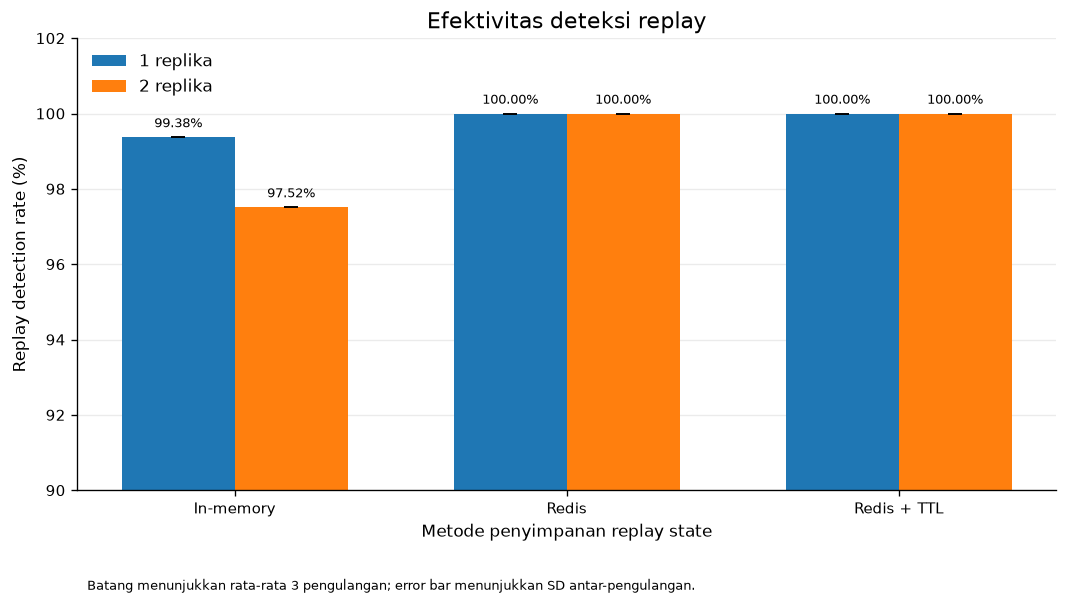

In [13]:
# 6.2 Replay detection rate per metode dan jumlah replika
security_plot = independent_security.copy()
security_plot["method"] = pd.Categorical(
    security_plot["method"], categories=method_order, ordered=True
)
security_plot = security_plot.groupby(
    ["method", "replica_count"], observed=True
)["replay_detection_rate_independent"].agg(["mean", "std"]).reset_index()

fig, ax = plt.subplots(figsize=(9, 5.2))
x = np.arange(len(method_order))
width = 0.34

for offset, replicas in [(-width/2, 1), (width/2, 2)]:
    part = security_plot[security_plot["replica_count"] == replicas].set_index("method").reindex(method_order)
    vals = part["mean"].to_numpy() * 100
    errs = part["std"].fillna(0).to_numpy() * 100
    bars = ax.bar(x + offset, vals, width, yerr=errs, capsize=4,
                  label=f"{replicas} replika")
    ax.bar_label(bars, labels=[f"{v:.2f}%" for v in vals], padding=4, fontsize=8)

ax.set_title("Efektivitas deteksi replay")
ax.set_ylabel("Replay detection rate (%)")
ax.set_xlabel("Metode penyimpanan replay state")
ax.set_xticks(x, [method_labels[m] for m in method_order])
ax.set_ylim(90, 102)
ax.legend(frameon=False)
ax.text(0.01, -0.22, "Batang menunjukkan rata-rata 3 pengulangan; error bar menunjukkan SD antar-pengulangan.",
        transform=ax.transAxes, fontsize=8)
finish_chart("validation_replay_detection_rate.png")


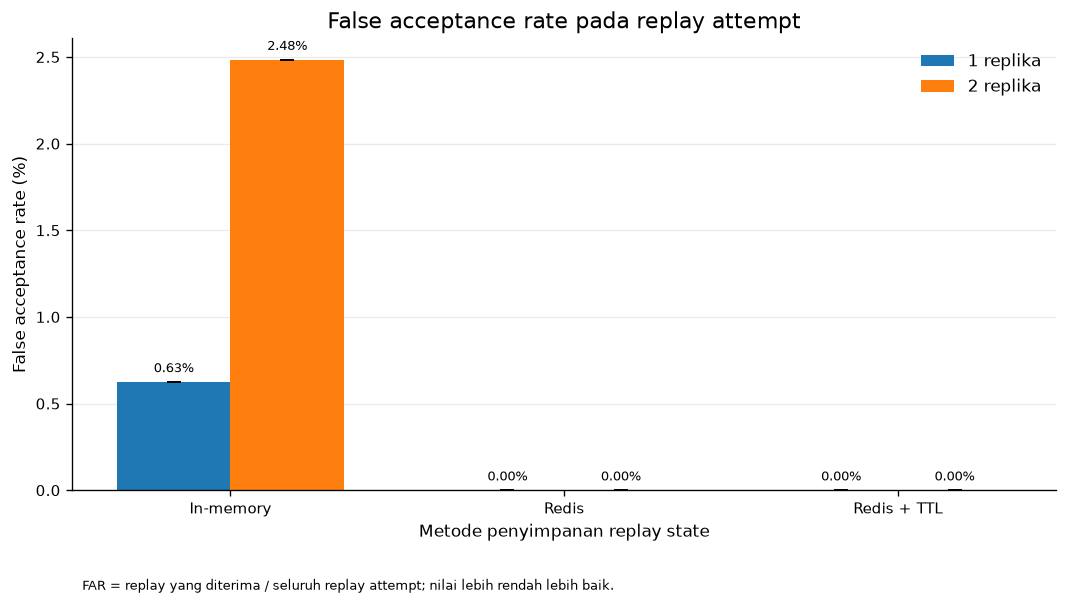

In [14]:
# 6.3 False acceptance rate (FAR) — semakin rendah semakin baik
far_plot = independent_security.copy()
far_plot["method"] = pd.Categorical(far_plot["method"], categories=method_order, ordered=True)
far_plot = far_plot.groupby(["method", "replica_count"], observed=True)[
    "false_acceptance_rate_independent"
].agg(["mean", "std"]).reset_index()

fig, ax = plt.subplots(figsize=(9, 5.2))
x = np.arange(len(method_order))
width = 0.34
for offset, replicas in [(-width/2, 1), (width/2, 2)]:
    part = far_plot[far_plot["replica_count"] == replicas].set_index("method").reindex(method_order)
    vals = part["mean"].to_numpy() * 100
    errs = part["std"].fillna(0).to_numpy() * 100
    bars = ax.bar(x + offset, vals, width, yerr=errs, capsize=4,
                  label=f"{replicas} replika")
    ax.bar_label(bars, labels=[f"{v:.2f}%" for v in vals], padding=4, fontsize=8)

ax.set_title("False acceptance rate pada replay attempt")
ax.set_ylabel("False acceptance rate (%)")
ax.set_xlabel("Metode penyimpanan replay state")
ax.set_xticks(x, [method_labels[m] for m in method_order])
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
ax.text(0.01, -0.22, "FAR = replay yang diterima / seluruh replay attempt; nilai lebih rendah lebih baik.",
        transform=ax.transAxes, fontsize=8)
finish_chart("validation_false_acceptance_rate.png")


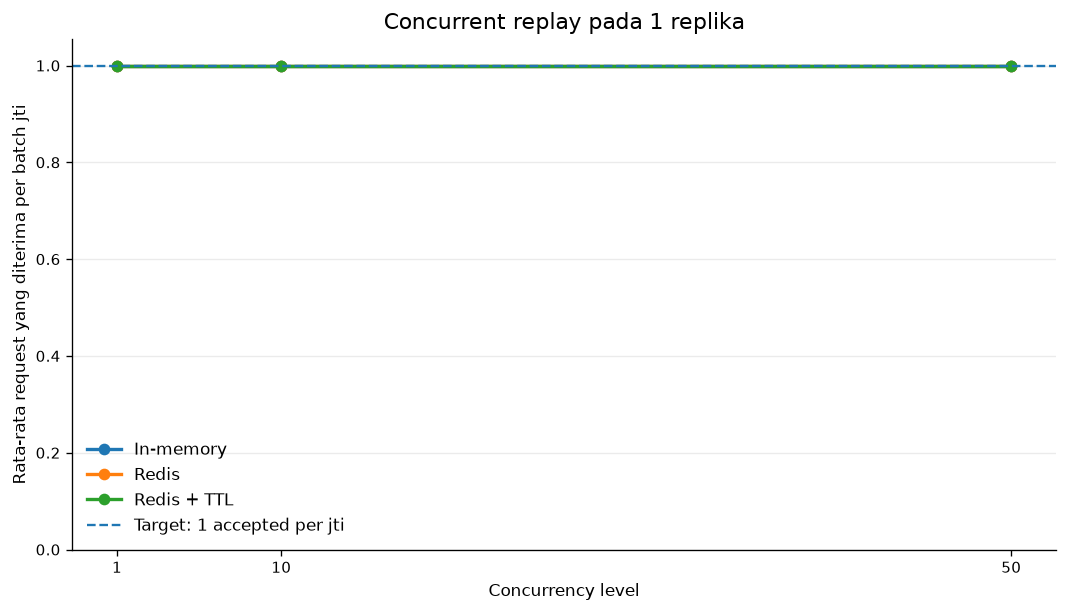

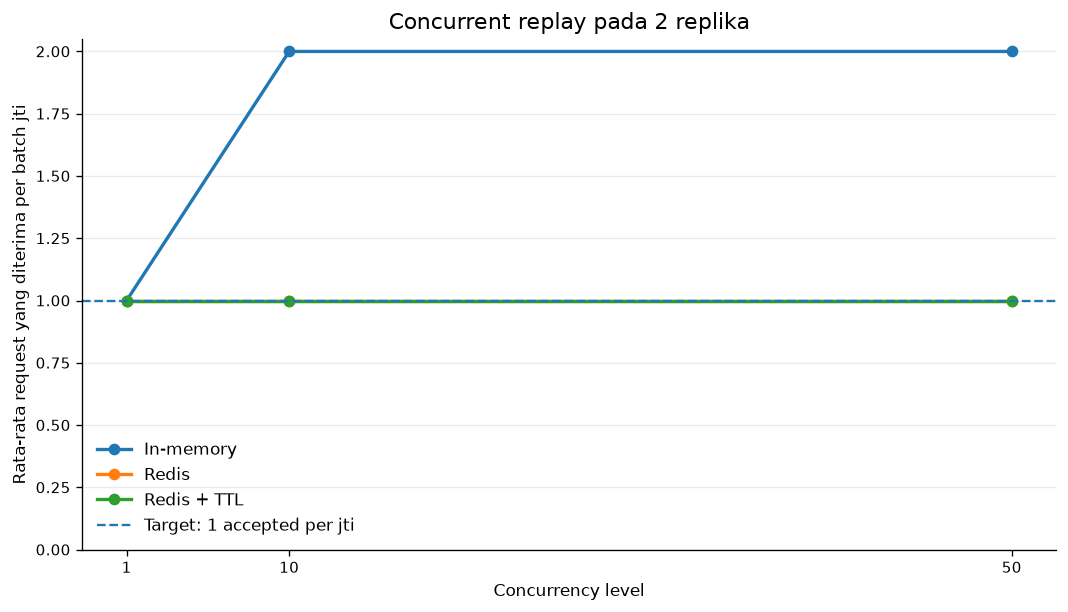

In [15]:
# 6.4 Jumlah request yang diterima per batch concurrent replay
# Idealnya tepat satu request diterima untuk setiap jti.
concurrent_plot = concurrent_batches.copy()
concurrent_plot["method"] = pd.Categorical(
    concurrent_plot["method"], categories=method_order, ordered=True
)
concurrent_means = concurrent_plot.groupby(
    ["method", "replica_count", "concurrency_level"], observed=True
)["accepted"].mean().reset_index()

for replicas in [1, 2]:
    fig, ax = plt.subplots(figsize=(9, 5.2))
    part = concurrent_means[concurrent_means["replica_count"] == replicas]
    for method in method_order:
        series = part[part["method"] == method].sort_values("concurrency_level")
        if not series.empty:
            ax.plot(series["concurrency_level"], series["accepted"],
                    marker="o", linewidth=2, markersize=6,
                    label=method_labels[method])
    ax.axhline(1, linestyle="--", linewidth=1.4,
               label="Target: 1 accepted per jti")
    ax.set_title(f"Concurrent replay pada {replicas} replika")
    ax.set_xlabel("Concurrency level")
    ax.set_ylabel("Rata-rata request yang diterima per batch jti")
    ax.set_xticks([1, 10, 50])
    ax.set_ylim(bottom=0)
    ax.legend(frameon=False)
    finish_chart(f"validation_concurrent_replay_{replicas}_replica.png")


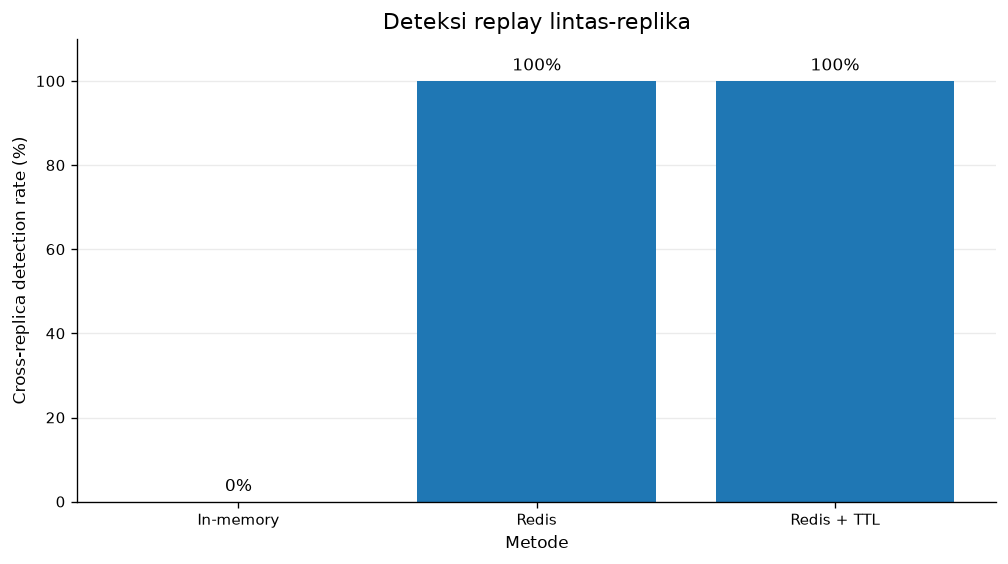

In [16]:
# 6.5 Cross-replica replay detection rate
cross_plot = cross_summary.copy()
cross_plot["method"] = pd.Categorical(
    cross_plot["method"], categories=method_order, ordered=True
)
cross_plot = cross_plot[cross_plot["replica_count"] == 2].sort_values("method")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
vals = cross_plot["cross_replica_detection_rate"].to_numpy() * 100
bars = ax.bar([method_labels[m] for m in cross_plot["method"].astype(str)], vals)
ax.bar_label(bars, labels=[f"{v:.0f}%" for v in vals], padding=4)
ax.set_title("Deteksi replay lintas-replika")
ax.set_ylabel("Cross-replica detection rate (%)")
ax.set_xlabel("Metode")
ax.set_ylim(0, 110)
finish_chart("validation_cross_replica_detection.png")


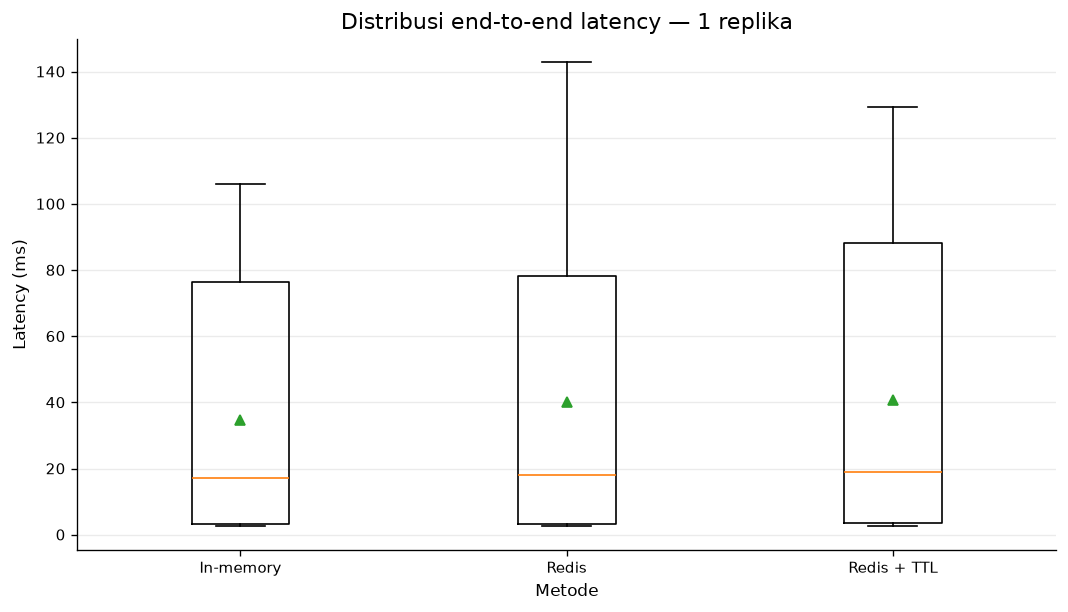

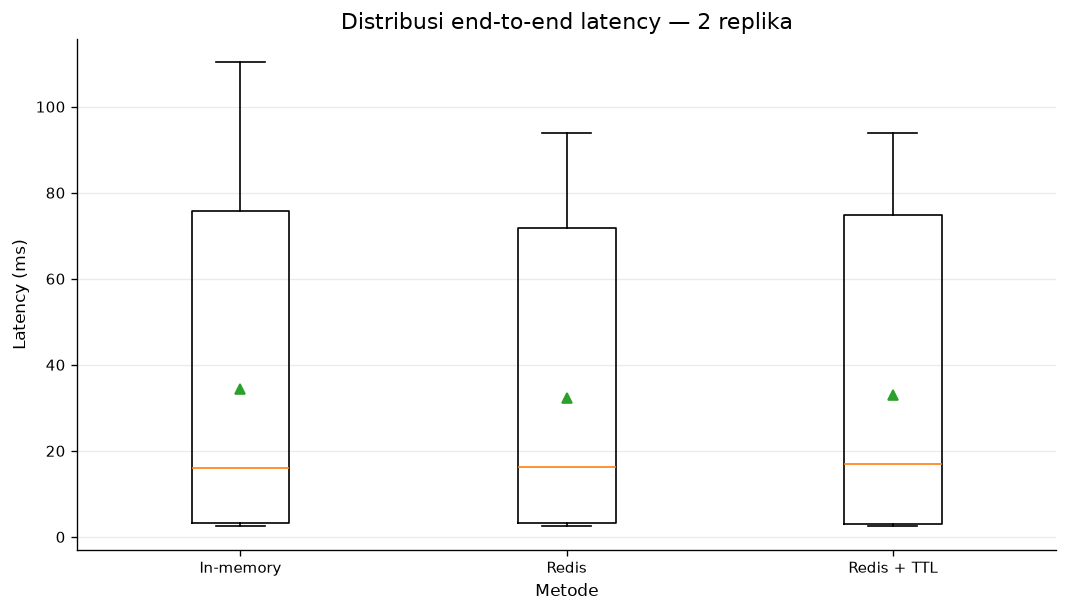

In [17]:
# 6.6 Distribusi end-to-end latency berdasarkan metode dan jumlah replika
perf_for_plot = performance_raw.copy()
perf_for_plot["method"] = pd.Categorical(
    perf_for_plot["method"], categories=method_order, ordered=True
)
for replicas in [1, 2]:
    fig, ax = plt.subplots(figsize=(9, 5.2))
    data, labels = [], []
    for method in method_order:
        values = perf_for_plot.loc[
            (perf_for_plot["method"] == method) &
            (perf_for_plot["replica_count"] == replicas),
            "latency_ms"
        ].dropna().to_numpy()
        data.append(values)
        labels.append(method_labels[method])
    ax.boxplot(data, tick_labels=labels, showfliers=True, showmeans=True)
    ax.set_title(f"Distribusi end-to-end latency — {replicas} replika")
    ax.set_ylabel("Latency (ms)")
    ax.set_xlabel("Metode")
    finish_chart(f"validation_latency_distribution_{replicas}_replica.png")


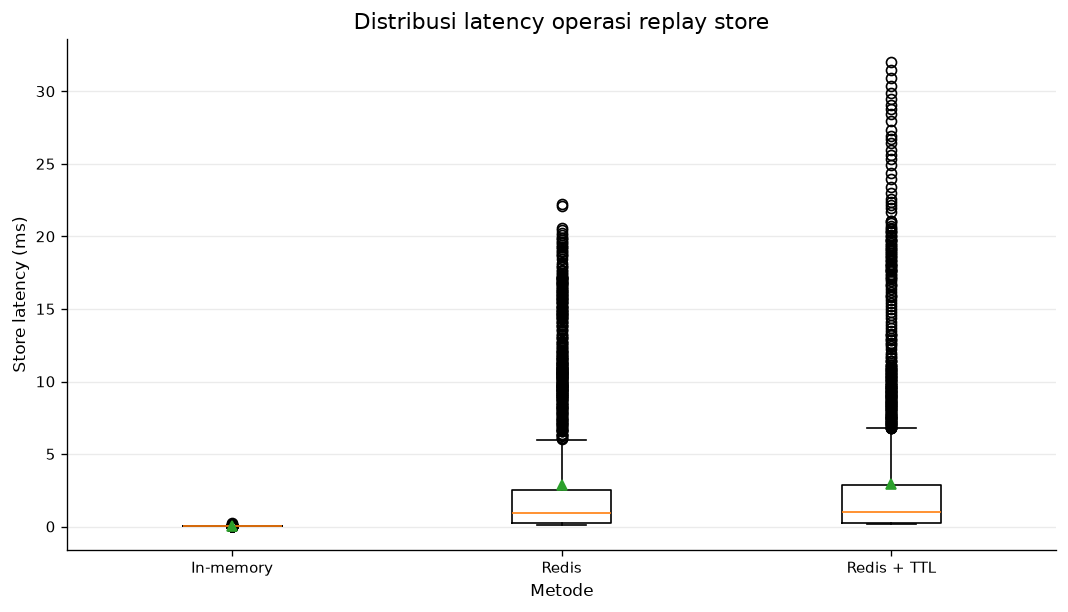

In [18]:
# 6.7 Distribusi latency operasi replay store
fig, ax = plt.subplots(figsize=(9, 5.2))
store_data, store_labels = [], []
for method in method_order:
    values = perf_for_plot.loc[
        perf_for_plot["method"] == method, "store_latency_ms"
    ].dropna().to_numpy()
    store_data.append(values)
    store_labels.append(method_labels[method])
ax.boxplot(store_data, tick_labels=store_labels, showfliers=True, showmeans=True)
ax.set_title("Distribusi latency operasi replay store")
ax.set_ylabel("Store latency (ms)")
ax.set_xlabel("Metode")
finish_chart("validation_store_latency_distribution.png")


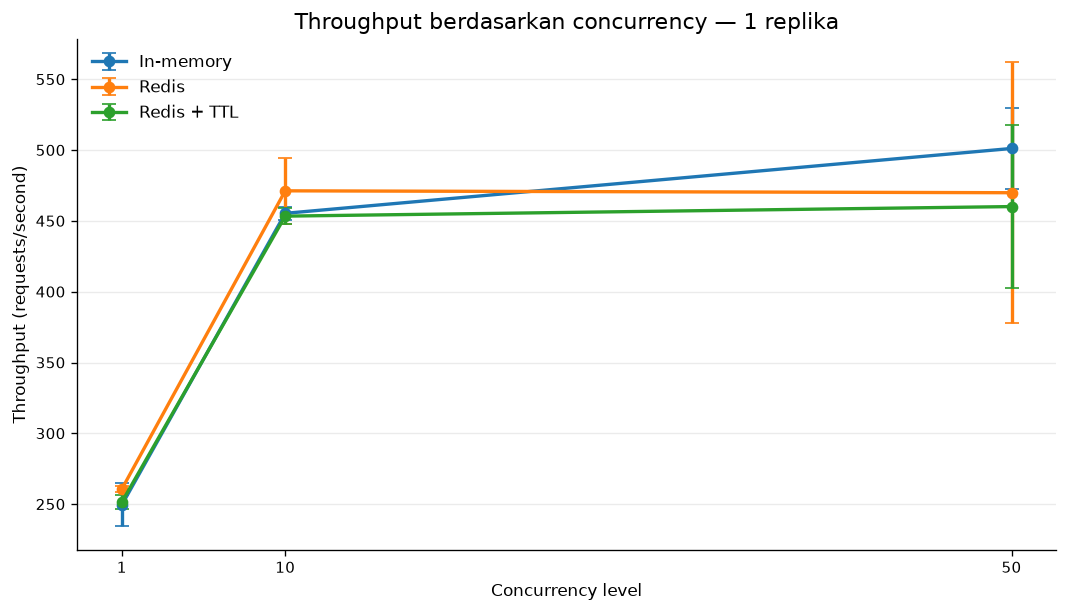

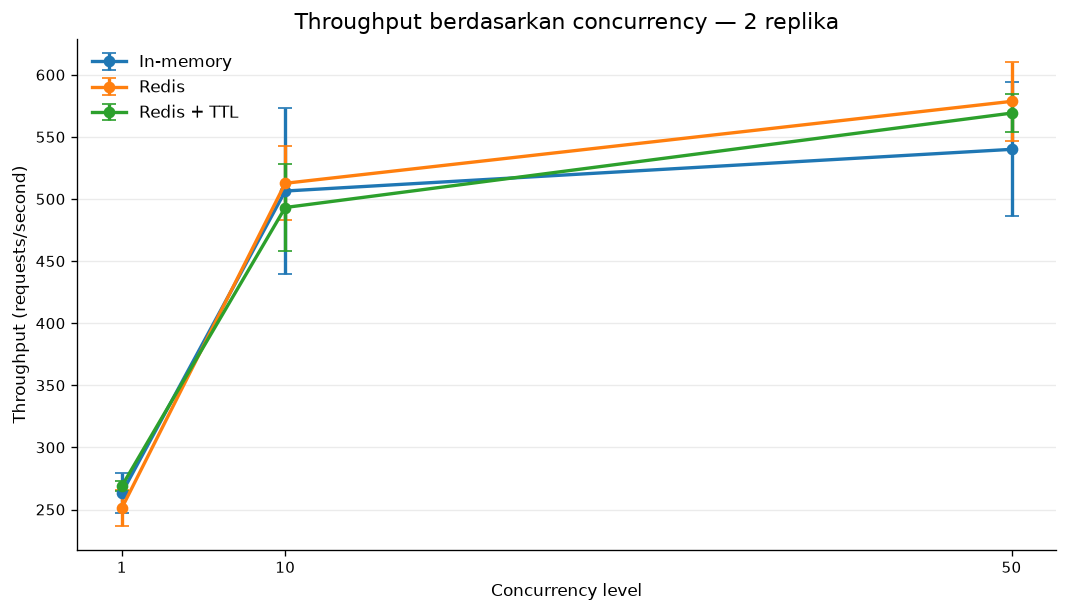

In [19]:
# 6.8 Throughput per tingkat concurrency
throughput_plot = throughput.copy()
throughput_plot["method"] = pd.Categorical(
    throughput_plot["method"], categories=method_order, ordered=True
)
throughput_means = throughput_plot.groupby(
    ["method", "replica_count", "concurrency_level"], observed=True
)["throughput_rps"].agg(["mean", "std"]).reset_index()

for replicas in [1, 2]:
    fig, ax = plt.subplots(figsize=(9, 5.2))
    part = throughput_means[throughput_means["replica_count"] == replicas]
    for method in method_order:
        series = part[part["method"] == method].sort_values("concurrency_level")
        if not series.empty:
            ax.errorbar(
                series["concurrency_level"], series["mean"],
                yerr=series["std"].fillna(0), marker="o",
                linewidth=2, capsize=4, label=method_labels[method]
            )
    ax.set_title(f"Throughput berdasarkan concurrency — {replicas} replika")
    ax.set_xlabel("Concurrency level")
    ax.set_ylabel("Throughput (requests/second)")
    ax.set_xticks([1, 10, 50])
    ax.legend(frameon=False)
    finish_chart(f"validation_throughput_{replicas}_replica.png")


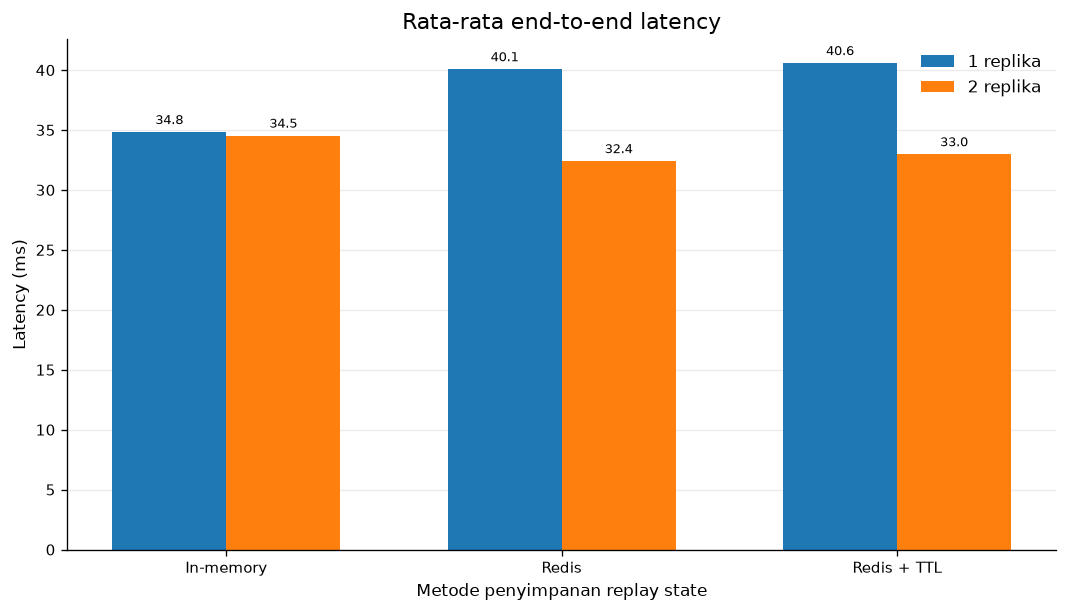

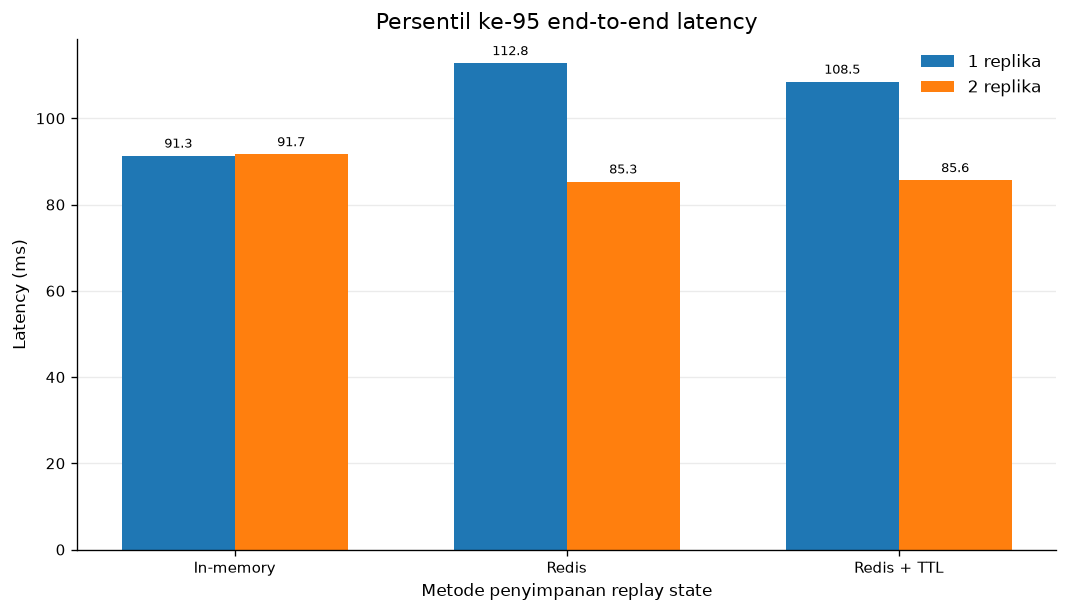

In [20]:
# 6.9 Ringkasan latency mean dan p95 per metode
latency_plot = independent_performance.copy()
latency_summary = latency_plot.groupby(
    ["method", "replica_count"], as_index=False
).agg(
    mean_latency_ms=("latency_mean_ms_calc", "mean"),
    p95_latency_ms=("latency_p95_ms_calc", "mean"),
)

for metric, title, filename in [
    ("mean_latency_ms", "Rata-rata end-to-end latency", "validation_mean_latency.png"),
    ("p95_latency_ms", "Persentil ke-95 end-to-end latency", "validation_p95_latency.png"),
]:
    fig, ax = plt.subplots(figsize=(9, 5.2))
    x = np.arange(len(method_order))
    width = 0.34
    for offset, replicas in [(-width/2, 1), (width/2, 2)]:
        part = latency_summary[latency_summary["replica_count"] == replicas].set_index("method").reindex(method_order)
        vals = part[metric].to_numpy()
        bars = ax.bar(x + offset, vals, width, label=f"{replicas} replika")
        ax.bar_label(bars, labels=[f"{v:.1f}" for v in vals], padding=3, fontsize=8)
    ax.set_title(title)
    ax.set_ylabel("Latency (ms)")
    ax.set_xlabel("Metode penyimpanan replay state")
    ax.set_xticks(x, [method_labels[m] for m in method_order])
    ax.legend(frameon=False)
    finish_chart(filename)


In [21]:
# 6.10 Daftar seluruh grafik yang dihasilkan
chart_files = sorted(chart_dir.glob("validation_*.png"))
chart_manifest = pd.DataFrame({
    "file": [p.name for p in chart_files],
    "size_kb": [round(p.stat().st_size / 1024, 1) for p in chart_files],
})
display(chart_manifest)
print(f"Total grafik validasi: {len(chart_manifest)}")


,file,size_kb
0,validation_concurrent_replay_1_replica.png,101.9
1,validation_concurrent_replay_2_replica.png,122.8
2,validation_cross_replica_detection.png,83.6
3,validation_false_acceptance_rate.png,114.3
4,validation_latency_distribution_1_replica.png,75.0
5,validation_latency_distribution_2_replica.png,71.3
6,validation_mean_latency.png,89.3
7,validation_p95_latency.png,93.8
8,validation_replay_detection_rate.png,123.1
9,validation_store_latency_distribution.png,115.9


Total grafik validasi: 12
